# 3. Eurostat – týždenné úmrtia (demo_r_mwk_20)

**Dataset:** *Deaths by week, sex and 20-year age group* · https://ec.europa.eu/eurostat/databrowser/view/demo_r_mwk_20/default/table  
**Obdobie:** od 2000 (SK približne od 2000) · Slovensko = `geo == "SK"`  
Sťahujeme priamo z Eurostat API (kópia na DBnomics nie je aktuálna).

Použitie: nadúmrtnosť počas chrípkových vĺn – porovnanie s očakávanou úmrtnosťou.

In [1]:
# Ak chýbajú knižnice, odkomentujte:
# !pip install pandas requests matplotlib
import os, io, datetime
import requests
import pandas as pd
import matplotlib.pyplot as plt

OUT = "data_raw"
os.makedirs(OUT, exist_ok=True)
DNES = datetime.date.today().isoformat()
print("Dátum stiahnutia:", DNES)

Dátum stiahnutia: 2026-10-26


## Stiahnutie (celý dataset, všetky krajiny)

In [2]:
URL = ("https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/demo_r_mwk_20"
       "?format=SDMX-CSV&startPeriod=2015-W01")
# Len Slovensko: .../demo_r_mwk_20/W.....SK?format=SDMX-CSV  – jednoduchšie je stiahnuť všetko a filtrovať.

r = requests.get(URL, timeout=600)
r.raise_for_status()
with open(f"{OUT}/eurostat_demo_r_mwk_20.csv", "wb") as f:
    f.write(r.content)
umrtia = pd.read_csv(io.BytesIO(r.content))
print(umrtia.shape)
umrtia.head()

(436738, 11)


,DATAFLOW,LAST UPDATE,freq,age,sex,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:DEMO_R_MWK_20(1.0),16/09/26 11:00:00,W,TOTAL,F,NR,AD,2015-W01,3.0,NaN,NaN
1,ESTAT:DEMO_R_MWK_20(1.0),16/09/26 11:00:00,W,TOTAL,F,NR,AD,2015-W02,3.0,NaN,NaN
2,ESTAT:DEMO_R_MWK_20(1.0),16/09/26 11:00:00,W,TOTAL,F,NR,AD,2015-W03,1.0,NaN,NaN
3,ESTAT:DEMO_R_MWK_20(1.0),16/09/26 11:00:00,W,TOTAL,F,NR,AD,2015-W04,1.0,NaN,NaN
4,ESTAT:DEMO_R_MWK_20(1.0),16/09/26 11:00:00,W,TOTAL,F,NR,AD,2015-W05,3.0,NaN,NaN


In [3]:
# Číselníky
for c in ["sex", "age", "unit", "geo"]:
    print(c, ":", sorted(umrtia[c].unique()))

sex : ['F', 'M', 'T']
age : ['TOTAL', 'UNK', 'Y20-39', 'Y40-59', 'Y60-79', 'Y_GE80', 'Y_LT20']
unit : ['NR']
geo : ['AD', 'AL', 'AM', 'AT', 'BE', 'BG', 'CH', 'CY', 'CZ', 'DE', 'DK', 'EE', 'EL', 'ES', 'EU27_2020', 'FI', 'FR', 'GE', 'HR', 'HU', 'IE', 'IS', 'IT', 'LI', 'LT', 'LU', 'LV', 'ME', 'MT', 'NL', 'NO', 'PL', 'PT', 'RO', 'RS', 'SE', 'SI', 'SK', 'UK']


## Slovensko

In [5]:
def iso_tyzden_na_datum(s):
    """'2024-W05' -> pondelok daného ISO týždňa"""
    return pd.to_datetime(s.str.replace("-W", "-") + "-1", format="%G-%V-%u")

In [6]:
sk = umrtia[(umrtia.geo == "SK")].copy()
sk = sk[sk.TIME_PERIOD.str.contains("W")]           # vyhodí prípadné neplatné týždne
sk = sk[~sk.TIME_PERIOD.str.endswith("W99")]         # W99 = neznámy týždeň
sk["datum"] = iso_tyzden_na_datum(sk.TIME_PERIOD)
sk = sk.rename(columns={"OBS_VALUE": "umrtia"})[["datum", "TIME_PERIOD", "sex", "age", "umrtia", "OBS_FLAG"]]
print(len(sk), "SK riadkov,", sk.datum.min().date(), "→", sk.datum.max().date())

12621 SK riadkov, 2014-12-29 → 2026-06-29


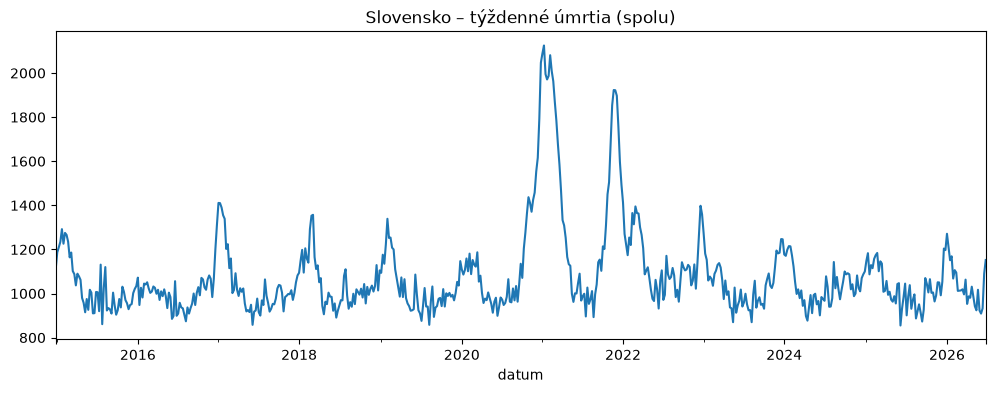

In [7]:
spolu = sk[(sk.sex == "T") & (sk.age == "TOTAL")].set_index("datum").umrtia
spolu.plot(figsize=(12, 4), title="Slovensko – týždenné úmrtia (spolu)")
plt.show()

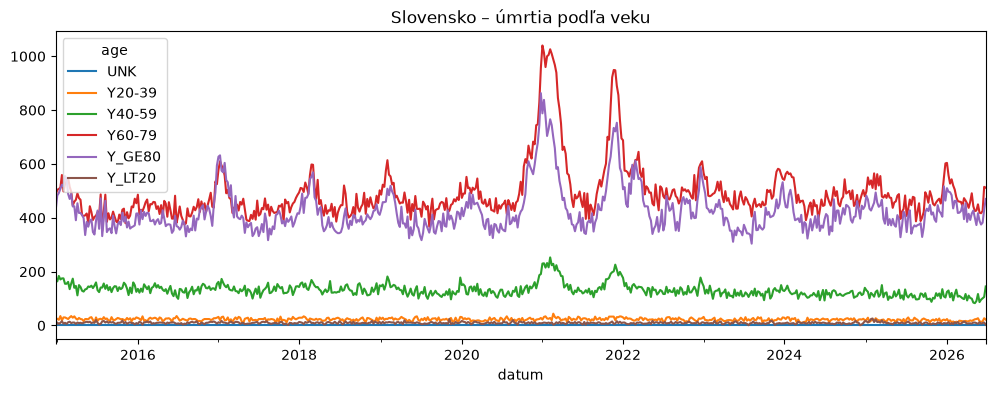

In [8]:
# Úmrtia podľa vekových skupín (obaja spolu)
sk[(sk.sex == "T") & (sk.age != "TOTAL")].pivot_table(index="datum", columns="age", values="umrtia") \
    .plot(figsize=(12, 4), title="Slovensko – úmrtia podľa veku")
plt.show()

In [ ]:
# Jednoduchá nadúmrtnosť: priemer rovnakého týždňa 2015–2019 ako základ
s = spolu.to_frame()
s["tyzden"] = s.index.isocalendar().week.values
zaklad = s[s.index.year.isin(range(2015, 2020))].groupby("tyzden").umrtia.mean()
s["ocakavane"] = s.tyzden.map(zaklad)
s["nadumrtnost_%"] = 100 * (s.umrtia / s.ocakavane - 1)
s.loc["2022":, "nadumrtnost_%"].plot(figsize=(12, 3), title="SK – nadúmrtnosť vs. 2015–2019 (%)")
plt.axhline(0, color="k", lw=.5); plt.show()

In [9]:
# Pozn.: posledné týždne bývajú neúplné (OBS_FLAG 'p' = provisional) – pri modelovaní ich zvážte.
print(sk.OBS_FLAG.value_counts(dropna=False))
sk.to_csv(f"{OUT}/eurostat_umrtia_SK.csv", index=False)
print("Uložené | stiahnuté:", DNES)

OBS_FLAG
NaN    9870
p      2751
Name: count, dtype: int64
Uložené | stiahnuté: 2026-10-26
